Point-at-target demo: paper's constrained PD-type control
Drone's position:
  x [default 0.0]: 4
  y [default 0.0]: 4
  z [default 1.0]: 4

Target position to point at:
  x [default 3.0]: 0
  y [default 3.0]: 0
  z [default 3.0]: 0

Drone at [4. 4. 4.], target at [0. 0. 0.], distance = 6.93 m
Target attitude quaternion [x,y,z,w] = [ 0.2798  0.1159 -0.8805  0.3647]
Initial attitude error: 41.4 degrees

Gain check: lambda_max(J)=20.74, need c < KD/lambda_max = 0.965; using c = 0.4
  Q > 0: True    P > 0: True
  Initial state inside the funnel (|q_i(0)|<rho_q0, |w_i(0)|<rho_w0): True

Blue drone: red nose = pointing direction; dotted blue line = its line of sight.
It reaches the gold sphere only when the drone is truly aimed at the target.

t=  0.0s   pointing error =  33.893 deg   |q_e| = 0.3537   theta_hat = 0.027
t=  1.0s   pointing error =  27.061 deg   |q_e| = 0.2989   theta_hat = 0.098
t=  2.0s   pointing error =  13.408 deg   |q_e| = 0.1704   theta_hat = 0.231
t=  3.1s   pointing e

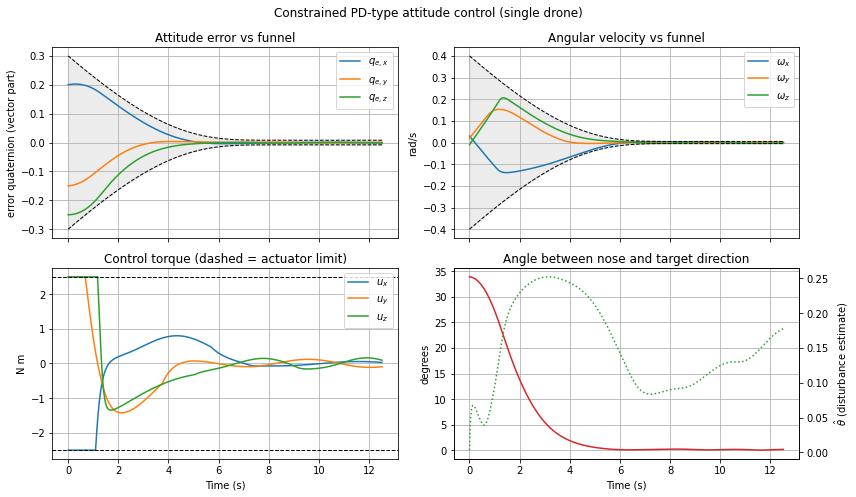

In [2]:
"""
ONE drone, pointing its nose at a target position, using the paper's
constrained PD-type attitude control (Golestani et al., IEEE Access 2022).

What it does
------------
1. Asks for the drone's position and a target position.
2. Works out the attitude (quaternion) that makes the drone's nose (+x axis)
   point at the target.
3. Starts the drone slightly mis-aimed (the paper's own initial error) and
   lets the controller turn it onto the target while keeping the attitude
   and the angular velocity inside the shrinking "funnel" (FTPPF, Eq. 8).
4. Opens the MuJoCo viewer, then plots the states against their funnels.

Equation map (paper -> code)
----------------------------
    Eq. 8   finite-time funnel rho(t)                -> ftppf()
    Eq. 11  eps1 = qv/rho_q,  eps2 = w/rho_w         -> constrained_controller()
    Eq. 12  u = -kp*qv - kd*w - u_cons               -> constrained_controller()
    Eq. 13  u_cons = [a(1-eps1)^-2 + b(1-eps2)^-2] s + theta_hat*sat(s/zeta)
            (sat() instead of sgn() is Remark 5 / Eq. 22, to reduce chatter)
    Eq. 14  d(theta_hat)/dt = (|s| - eta2*theta_hat)/eta1  -> main loop

Install / run
-------------
    pip install mujoco numpy matplotlib
    python drone_pointing_paper_control.py
"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ============================================================================
# 1. Paper's physical model (Eq. 1 / 5) and disturbance
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])          # kg m^2  (Section IV)
U_MAX = 2.5                                # N m, actuator saturation (Section IV)
FULLINERTIA = "20 17 15 1.2 0.9 1.4"       # MuJoCo order: xx yy zz xy xz yz


def disturbance(t):
    """External torque d(t) from Section IV (N m)."""
    return np.array([0.05 * np.sin(t),
                     0.10 * np.sin(1.2 * t),
                     0.15 * np.sin(1.5 * t)])


def saturate(u):
    return np.clip(u, -U_MAX, U_MAX)


# ============================================================================
# 2. Funnel and controller parameters
# ============================================================================
# Funnel (Eq. 8). Values from Section IV of the paper.
RHO_Q0, RHO_QINF = 0.3, 0.008      # attitude funnel: start width, final width
RHO_W0, RHO_WINF = 0.4, 0.005      # angular-velocity funnel
KAPPA = 2.5
TS = 10.0                          # settling time of the funnel (s)

# Controller (Section IV)
KP, KD = 40.0, 20.0
ALPHA, BETA = 1.5, 1.2
ETA1 = 0.1


def eta2(t):
    return 2.0 * np.exp(-0.5 * t)  # decaying leakage, integral is finite


# Not given numerically in the paper -> chosen here.
C_GAIN = 0.4    # the proof needs c "sufficiently small": KD > c*lambda_max(J)
ZETA = 0.01     # boundary-layer width for sat(s/zeta)
EPS_MAX = 0.999  # numerical guard only: avoids dividing by zero at eps = 1

# Initial ATTITUDE ERROR. This is the paper's Part-1 initial quaternion, so the
# paper's funnel values above are valid (|q_i(0)| < RHO_Q0). The drone starts
# this far (about 41 degrees) away from pointing at the target.
# If you change it, keep every |component| of the vector part below RHO_Q0.
Q_OFFSET = np.array([0.2, -0.15, -0.25, 0.9354])   # [qx, qy, qz, q4]
W_START = np.array([0.03, 0.02, -0.01])            # rad/s (paper's omega(0))

T_END = 25.0
STEPS_PER_FRAME = 10     # physics steps per viewer refresh


def ftppf(t, rho0, rhoT, kappa, Ts):
    """Finite-time prescribed performance function, Eq. 8."""
    if t < Ts:
        return (rho0 - rhoT * (1.0 + t / Ts)) * np.exp(kappa * t / (t - Ts)) + rhoT
    return rhoT


def check_paper_conditions():
    """Print whether the gain conditions used in the paper's proof hold."""
    lam = np.linalg.eigvalsh(J)
    lmin, lmax = lam[0], lam[-1]
    q_ok = KD - C_GAIN * lmax > 0                       # Q positive definite
    p_block = np.array([[2 * (KP + C_GAIN * KD), -C_GAIN * lmax],
                        [-C_GAIN * lmax, lmin]])
    p_ok = bool(np.all(np.linalg.eigvalsh(p_block) > 0))  # P positive definite
    print(f"Gain check: lambda_max(J)={lmax:.2f}, need c < KD/lambda_max = "
          f"{KD / lmax:.3f}; using c = {C_GAIN}")
    print(f"  Q > 0: {q_ok}    P > 0: {p_ok}")
    ic_ok = np.all(np.abs(Q_OFFSET[:3]) < RHO_Q0) and np.all(np.abs(W_START) < RHO_W0)
    print(f"  Initial state inside the funnel (|q_i(0)|<rho_q0, |w_i(0)|<rho_w0): {ic_ok}\n")


# ============================================================================
# 3. Quaternion helpers (scalar-LAST, as in the paper: q = [qv, q4])
# ============================================================================
def quat_mult(q1, q2):
    v1, s1 = q1[:3], q1[3]
    v2, s2 = q2[:3], q2[3]
    return np.concatenate([s1 * v2 + s2 * v1 + np.cross(v1, v2),
                           [s1 * s2 - np.dot(v1, v2)]])


def quat_conj(q):
    return np.concatenate([-q[:3], [q[3]]])


def quat_rotate(q, v):
    qv, s = q[:3], q[3]
    return v + 2 * s * np.cross(qv, v) + 2 * np.cross(qv, np.cross(qv, v))


def euler_to_quat(roll_deg, pitch_deg, yaw_deg):
    """Aerospace ZYX Euler angles (deg) -> quaternion [x, y, z, w]."""
    r, p, y = np.radians([roll_deg, pitch_deg, yaw_deg])
    cr, sr = np.cos(r / 2), np.sin(r / 2)
    cp, sp = np.cos(p / 2), np.sin(p / 2)
    cy, sy = np.cos(y / 2), np.sin(y / 2)
    return np.array([sr * cp * cy - cr * sp * sy,
                     cr * sp * cy + sr * cp * sy,
                     cr * cp * sy - sr * sp * cy,
                     cr * cp * cy + sr * sp * sy])


def direction_to_quat(direction):
    """Quaternion whose body +x axis (the nose) points along `direction`, roll = 0."""
    v = direction / np.linalg.norm(direction)
    yaw = np.degrees(np.arctan2(v[1], v[0]))
    pitch = np.degrees(np.arctan2(-v[2], np.hypot(v[0], v[1])))
    return euler_to_quat(0.0, pitch, yaw)


def attitude_error(q_current, q_target):
    """Error quaternion q_e = q_target^-1 (x) q_current (shortest rotation)."""
    q_e = quat_mult(quat_conj(q_target), q_current)
    return -q_e if q_e[3] < 0 else q_e


# ============================================================================
# 4. The paper's controller (Eqs. 11-14 / 22), acting on the error state
# ============================================================================
def constrained_controller(qv_e, omega, theta_hat, t):
    rho_q = ftppf(t, RHO_Q0, RHO_QINF, KAPPA, TS)
    rho_w = ftppf(t, RHO_W0, RHO_WINF, KAPPA, TS)

    eps1 = np.clip(qv_e / rho_q, -EPS_MAX, EPS_MAX)    # Eq. 11
    eps2 = np.clip(omega / rho_w, -EPS_MAX, EPS_MAX)

    s = omega + C_GAIN * qv_e                          # s = w + c*qv

    # The paper writes the bracket as a scalar although eps is a vector;
    # here it is applied element-wise (a diagonal gain on s).
    barrier = ALPHA * (1.0 - eps1) ** -2 + BETA * (1.0 - eps2) ** -2
    u_cons = barrier * s + theta_hat * np.clip(s / ZETA, -1.0, 1.0)

    u = -KP * qv_e - KD * omega - u_cons               # Eq. 12 / 22
    return u, s, rho_q, rho_w


# ============================================================================
# 5. Scene description (one drone, one target)
# ============================================================================
def dashed_los_xml(end, rgba, start=0.45, dash=0.09, gap=0.07, radius=0.022):
    """Dotted line of sight along the drone's own +x axis, from the nose to `end`."""
    segs, x = [], start
    while x < end:
        x2 = min(x + dash, end)
        segs.append(f'<geom type="cylinder" fromto="{x:.3f} 0 0  {x2:.3f} 0 0" '
                    f'size="{radius}" rgba="{rgba}" contype="0" conaffinity="0"/>')
        x += dash + gap
    return "\n      ".join(segs)


def build_xml(drone_pos, target_pos):
    dist = float(np.linalg.norm(target_pos - drone_pos))
    center = (drone_pos + target_pos) / 2
    floor_size = max(6.0, dist * 1.5)
    los = dashed_los_xml(dist, "0.2 0.5 1.0 0.9")   # ends exactly at the target distance
    return f"""
<mujoco model="pointing_demo">
  <compiler angle="degree"/>
  <option timestep="0.002" gravity="0 0 0"/>
  <visual><headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/></visual>
  <asset>
    <texture type="skybox" builtin="gradient" rgb1="0.05 0.05 0.12" rgb2="0 0 0" width="256" height="256"/>
    <texture name="grid" type="2d" builtin="checker" rgb1="0.25 0.25 0.3" rgb2="0.18 0.18 0.22" width="512" height="512"/>
    <material name="grid" texture="grid" texrepeat="10 10" reflectance="0.05"/>
  </asset>
  <worldbody>
    <light pos="{center[0]:.2f} {center[1]:.2f} {center[2] + 6:.2f}" dir="0 0 -1" diffuse="1 1 1"/>
    <geom name="floor" type="plane" size="{floor_size:.2f} {floor_size:.2f} 0.1" material="grid"/>

    <!-- target (gold sphere) -->
    <geom type="sphere" pos="{target_pos[0]:.4f} {target_pos[1]:.4f} {target_pos[2]:.4f}"
          size="0.1" rgba="1.0 0.8 0.1 0.9" contype="0" conaffinity="0"/>
    <!-- faint static reference line: drone position -> target -->
    <geom type="cylinder" fromto="{drone_pos[0]:.4f} {drone_pos[1]:.4f} {drone_pos[2]:.4f}  {target_pos[0]:.4f} {target_pos[1]:.4f} {target_pos[2]:.4f}"
          size="0.008" rgba="0.8 0.8 0.8 0.35" contype="0" conaffinity="0"/>

    <!-- the drone: everything inside <body> turns with it, including the dotted line of sight -->
    <body name="drone" pos="{drone_pos[0]:.4f} {drone_pos[1]:.4f} {drone_pos[2]:.4f}">
      <joint name="root" type="free"/>
      <inertial pos="0 0 0" mass="6.0" fullinertia="{FULLINERTIA}"/>
      <geom type="box" size="0.18 0.18 0.18" rgba="0.15 0.35 0.75 1" contype="0" conaffinity="0"/>
      <geom type="box" pos="0 0.45 0"  size="0.05 0.28 0.09" rgba="0.1 0.5 0.9 0.6" contype="0" conaffinity="0"/>
      <geom type="box" pos="0 -0.45 0" size="0.05 0.28 0.09" rgba="0.1 0.5 0.9 0.6" contype="0" conaffinity="0"/>
      <geom type="cylinder" fromto="0.18 0 0  0.45 0 0" size="0.05" rgba="0.9 0.2 0.2 1" contype="0" conaffinity="0"/>
      {los}
    </body>
  </worldbody>
  <actuator>
    <motor name="tx" joint="root" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
    <motor name="ty" joint="root" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
    <motor name="tz" joint="root" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
  </actuator>
</mujoco>
"""


# ============================================================================
# 6. Input helpers and plotting
# ============================================================================
def ask_float(prompt, default):
    raw = input(f"{prompt} [default {default}]: ").strip()
    if raw == "":
        return default
    try:
        return float(raw)
    except ValueError:
        print(f"  couldn't parse '{raw}', using {default}")
        return default


def plot_results(log):
    import matplotlib.pyplot as plt
    t = np.array(log["t"])
    qv, w, u = np.array(log["qv"]), np.array(log["w"]), np.array(log["u"])
    rq, rw = np.array(log["rho_q"]), np.array(log["rho_w"])

    fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for i, name in enumerate(["x", "y", "z"]):
        ax[0, 0].plot(t, qv[:, i], label=f"$q_{{e,{name}}}$")
        ax[0, 1].plot(t, w[:, i], label=f"$\\omega_{name}$")
        ax[1, 0].plot(t, u[:, i], label=f"$u_{name}$")
    for a, rho, title, yl in [(ax[0, 0], rq, "Attitude error vs funnel", "error quaternion (vector part)"),
                              (ax[0, 1], rw, "Angular velocity vs funnel", "rad/s")]:
        a.plot(t, rho, "k--", lw=1)
        a.plot(t, -rho, "k--", lw=1)
        a.fill_between(t, -rho, rho, color="gray", alpha=0.15)
        a.set_title(title)
        a.set_ylabel(yl)
    ax[1, 0].axhline(U_MAX, color="k", ls="--", lw=1)
    ax[1, 0].axhline(-U_MAX, color="k", ls="--", lw=1)
    ax[1, 0].set_title("Control torque (dashed = actuator limit)")
    ax[1, 0].set_ylabel("N m")

    ax[1, 1].plot(t, log["point_err"], color="tab:red", label="pointing error")
    ax[1, 1].set_ylabel("degrees")
    ax[1, 1].set_title("Angle between nose and target direction")
    twin = ax[1, 1].twinx()
    twin.plot(t, log["theta_hat"], color="tab:green", ls=":", label=r"$\hat\theta$")
    twin.set_ylabel(r"$\hat\theta$ (disturbance estimate)")

    for a in ax.ravel():
        a.grid(True)
    for a in ax[0, :]:
        a.legend(loc="upper right")
    ax[1, 0].legend(loc="upper right")
    ax[1, 0].set_xlabel("Time (s)")
    ax[1, 1].set_xlabel("Time (s)")
    fig.suptitle("Constrained PD-type attitude control (single drone)")
    fig.tight_layout()
    plt.show()


# ============================================================================
# 7. Main
# ============================================================================
def main():
    print("=" * 60)
    print("Point-at-target demo: paper's constrained PD-type control")
    print("=" * 60)
    print("Drone's position:")
    drone_pos = np.array([ask_float("  x", 0.0), ask_float("  y", 0.0), ask_float("  z", 1.0)])
    print("\nTarget position to point at:")
    target_pos = np.array([ask_float("  x", 3.0), ask_float("  y", 3.0), ask_float("  z", 3.0)])

    direction = target_pos - drone_pos
    if np.linalg.norm(direction) < 1e-6:
        print("\n  Target equals drone position -- pointing along +x instead.")
        direction = np.array([1.0, 0.0, 0.0])
    dist = np.linalg.norm(direction)
    target_dir = direction / dist

    q_target = direction_to_quat(direction)
    # Start the drone at q_target rotated by the paper's initial error, so that
    # the initial ERROR quaternion equals Q_OFFSET exactly.
    q_off = Q_OFFSET / np.linalg.norm(Q_OFFSET)
    q_start = quat_mult(q_target, q_off)

    print(f"\nDrone at {drone_pos}, target at {target_pos}, distance = {dist:.2f} m")
    print(f"Target attitude quaternion [x,y,z,w] = {np.round(q_target, 4)}")
    print(f"Initial attitude error: {2 * np.degrees(np.arcsin(np.linalg.norm(q_off[:3]))):.1f} degrees\n")
    check_paper_conditions()

    model = mujoco.MjModel.from_xml_string(build_xml(drone_pos, target_pos))
    data = mujoco.MjData(model)
    jid = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root")
    qadr, dadr = model.jnt_qposadr[jid], model.jnt_dofadr[jid]

    # MuJoCo stores quaternions as [w, x, y, z]; the paper uses [x, y, z, w].
    data.qpos[qadr + 3: qadr + 7] = [q_start[3], q_start[0], q_start[1], q_start[2]]
    data.qvel[dadr + 3: dadr + 6] = W_START       # body-frame angular velocity

    dt = model.opt.timestep
    theta_hat = 0.0
    log = {k: [] for k in ["t", "qv", "w", "u", "rho_q", "rho_w", "theta_hat", "point_err"]}
    eps_q_max = eps_w_max = 0.0

    with mujoco.viewer.launch_passive(model, data) as viewer:
        viewer.cam.lookat[:] = (drone_pos + target_pos) / 2
        viewer.cam.distance = max(6.0, dist * 2.0)
        viewer.cam.azimuth, viewer.cam.elevation = 100, -20
        print("Blue drone: red nose = pointing direction; dotted blue line = its line of sight.")
        print("It reaches the gold sphere only when the drone is truly aimed at the target.\n")

        last_print = -1.0
        while viewer.is_running() and data.time < T_END:
            frame_start = time.time()
            for _ in range(STEPS_PER_FRAME):
                t = data.time

                mj = data.qpos[qadr + 3: qadr + 7]
                q_cur = np.array([mj[1], mj[2], mj[3], mj[0]])
                qv_e = attitude_error(q_cur, q_target)[:3]
                omega = data.qvel[dadr + 3: dadr + 6].copy()

                u, s, rho_q, rho_w = constrained_controller(qv_e, omega, theta_hat, t)
                u_sat = saturate(u)
                data.ctrl[0:3] = u_sat
                data.qfrc_applied[dadr + 3: dadr + 6] = disturbance(t)

                theta_hat += dt * (np.linalg.norm(s) - eta2(t) * theta_hat) / ETA1   # Eq. 14

                nose = quat_rotate(q_cur, np.array([1.0, 0.0, 0.0]))
                point_err = np.degrees(np.arccos(np.clip(np.dot(nose, target_dir), -1.0, 1.0)))

                eps_q_max = max(eps_q_max, np.max(np.abs(qv_e)) / rho_q)
                eps_w_max = max(eps_w_max, np.max(np.abs(omega)) / rho_w)
                for k, v in zip(log, [t, qv_e, omega, u_sat, rho_q, rho_w, theta_hat, point_err]):
                    log[k].append(v)

                mujoco.mj_step(model, data)

            viewer.sync()
            if data.time - last_print >= 1.0:
                print(f"t={data.time:5.1f}s   pointing error = {point_err:7.3f} deg   "
                      f"|q_e| = {np.linalg.norm(qv_e):.4f}   theta_hat = {theta_hat:.3f}")
                last_print = data.time
            spare = STEPS_PER_FRAME * dt - (time.time() - frame_start)
            if spare > 0:
                time.sleep(spare)

    print(f"\nFunnel check: max |q_i|/rho_q = {eps_q_max:.3f}, max |w_i|/rho_w = {eps_w_max:.3f} "
          f"({'inside' if max(eps_q_max, eps_w_max) < 1 else 'OUTSIDE'} the funnel; must stay < 1)")
    if log["t"]:
        plot_results(log)


if __name__ == "__main__":
    main()

## 